In [1]:
%load_ext autoreload
%autoreload 2

import pandas as pd
import numpy as np
import os
import itertools
import warnings
from tqdm import tqdm
from scripts import process
from scripts import analyse
from scripts import scrp_hrh
from scripts import scrp_serv
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import plotly.graph_objects as go
import math
from IPython.display import clear_output

pd.set_option('display.max_rows', 300)
pd.set_option('future.no_silent_downcasting', True)
warnings.simplefilter('ignore', DeprecationWarning)

# Set a standardized style of graph
plt.rcParams.update({
    "font.size": 10,  # Standard font size for high-impact journals
    "font.family": "Arial",  # Standard font
    "axes.linewidth": 1,  # Line thickness
    "grid.alpha": 0.6,  # Grid transparency
    "grid.linestyle": "--",  # Grid style
})

/var/folders/y7/8_qm7_795fnd2fb2ztv5_j_w0000gn/T/ipykernel_7713/3788301701.py:21: Pandas4Warning: 'future.no_silent_downcasting' is deprecated, please refrain from using it.
  pd.set_option('future.no_silent_downcasting', True)


### Popolation Modelling

In [4]:
# Import Thailand population data
pop_file = 'pop'
data_dir = 'data/pop/age'
output_dir = 'output/clean'

years = range(2013,2025)

pop_country = pd.DataFrame()
pop_hregion = pd.DataFrame()
pop_prov = pd.DataFrame()
pop_dist = pd.DataFrame()

id_cols = ['year', 'prov_id', 'prov', 'dist_id', 'dist', 'subdist_id', 'subdist', 'village_id', 'village']

def sum_age_range(pop, lo, hi):
    cols = [f'{sex}_yr{age}' for age in range(lo, hi + 1) for sex in ('m', 'f')]
    return pop[cols].sum(axis=1)

def add_age_bands(df):
    age_bands = pd.DataFrame({
        'newborn': df['m_yr0'] + df['f_yr0'],
        'child': sum_age_range(df, 1, 14),
        'reproductive': sum_age_range(df, 15, 44),
        'pre-ageing': sum_age_range(df, 45, 64),
        'ageing': sum_age_range(df, 65, 101),
    })
    return pd.concat([df, age_bands], axis=1).copy()

for year in years:

    pop_file = f'data/pop/age/pop_{year}.xlsx'
    pop = pd.read_excel(pop_file, sheet_name='pop')
    pop = process.DataCleaning.update_column_name(pop, 'data/pop/age/data_dict-pop.xlsx')
    pop = pop.copy()  # read_excel leaves one block per column; consolidate before adding/aggregating columns
    pop['year'] = year
    pop['dist_id'] = pop['subdist_id'].astype(str).str[:4].astype(int)  # raw dist_id is unreliable; derive from subdist_id instead

    value_cols = [c for c in pop.columns if c not in id_cols]

    # Create population dataset in district level
    dist_yr = pop.groupby(['year', 'prov_id', 'dist_id'], as_index=False)[value_cols].sum()
    dist_yr = add_age_bands(dist_yr)
    pop_dist = pd.concat([pop_dist, dist_yr], ignore_index=True)

    # Create population dataset in provincial level
    prov_yr = pop.groupby(['year', 'prov_id'], as_index=False)[value_cols].sum()
    prov_yr = add_age_bands(prov_yr)
    pop_prov = pd.concat([pop_prov, prov_yr], ignore_index=True)

    # Create population dataset in health regional level (province name is only needed
    # transiently to look up the region, then dropped in favor of hregion_id)
    hregion_yr = pop.groupby(['year', 'prov'], as_index=False)[value_cols].sum()
    hregion_yr['prov'] = hregion_yr['prov'].apply(lambda x: x if x in ['กรุงเทพมหานคร', 'ทั่วประเทศ'] else x[7:])
    hregion_yr = process.DataManipulation.mapping(hregion_yr, 'prov')
    hregion_yr['hregion_id'] = hregion_yr['prov'].apply(lambda x: x[-2:] if len(x) == 15 else x[-1:])
    hregion_yr = hregion_yr.drop(columns='prov').groupby(['year', 'hregion_id'], as_index=False)[value_cols].sum()
    hregion_yr = add_age_bands(hregion_yr)
    pop_hregion = pd.concat([pop_hregion, hregion_yr], ignore_index=True)

    # Create population dataset in country level
    country_yr = pop.groupby('year', as_index=False)[value_cols].sum()
    country_yr = add_age_bands(country_yr)
    pop_country = pd.concat([pop_country, country_yr], ignore_index=True)

pop_dist.to_csv('output/clean/pop_age/pop_dist.csv', index=False)
pop_prov.to_csv('output/clean/pop_age/pop_prov.csv', index=False)
pop_hregion.to_csv('output/clean/pop_age/pop_hregion.csv', index=False)
pop_country.to_csv('output/clean/pop_age/pop_country.csv', index=False)

clear_output()
display(pop_dist.head())

,year,prov_id,dist_id,m_yr0,f_yr0,m_yr1,f_yr1,m_yr2,f_yr2,m_yr3,...,f_move,total_move,pop_male,pop_female,pop,newborn,child,reproductive,pre-ageing,ageing
0,2013,10,1001,150,123,177,141,160,148,144,...,30,160,27279,29405,56684,273,7899,22756,16197,7541
1,2013,10,1002,332,316,419,334,399,337,388,...,436,2243,57158,49653,106811,648,11732,44929,28596,13979
2,2013,10,1003,1051,1016,1152,1079,1153,1082,1130,...,70,179,77988,81974,159962,2067,33298,77529,36706,9475
3,2013,10,1004,124,110,146,119,148,117,138,...,492,1037,21792,24322,46114,234,4419,16625,12108,5840
4,2013,10,1005,828,734,942,893,986,889,984,...,171,919,91208,99336,190544,1562,27804,88439,53583,16166


In [3]:
# Build the population model

In [5]:
# --- Cohort-component population projection, district level, 15-year horizon ---
# Method: age each single-year cohort forward using a survival+net-migration ratio
# implied by comparing consecutive years' age distributions (we only observe
# stocks, not vital rates, so this ratio bundles mortality and migration together).
# District-level ratios are noisy for small districts (see earlier prototype), so
# each (district, sex, age) ratio falls back to its province-level equivalent
# whenever the district's historical source cohort was too small to trust.

pop_dist = pd.read_csv('output/clean/pop_age/pop_dist.csv')
pop_prov = pd.read_csv('output/clean/pop_age/pop_prov.csv')
pop_dist = pop_dist[pop_dist['pop'] > 0].copy()  # drop a handful of zero-pop artifact rows

MAX_SINGLE_AGE = 99  # ages 0..99 kept as single years; 100 & 101 merged into an open '100+' group

def add_100plus(df):
    df = df.copy()
    for sex in ('m', 'f'):
        df[f'{sex}_yr100p'] = df[f'{sex}_yr100'] + df[f'{sex}_yr101']
    return df

pop_dist = add_100plus(pop_dist)
pop_prov = add_100plus(pop_prov)

def state_col(sex, age):
    return f'{sex}_yr{age}'

In [6]:
def cohort_rates(df, id_col):
    """
    For each group (district or province), estimate:
      - ratios[gid][sex]: array of 100 ratios. Index a-1 (a=1..99) is the ratio
        feeding cohort age a from age a-1 the previous year; index 99 feeds the
        open '100+' group from the pooled (age 99 + existing 100+) cohort.
      - src_size[gid][sex]: average historical size of the source cohort behind
        each ratio (used later to decide whether to trust the district's own
        ratio or fall back to its province).
      - birth_rate[gid]: mean(total births in year t+1 / reproductive women in year t)
      - birth_sex_ratio[gid]: mean male share of births
      - repro_size[gid]: average reproductive-women count (trust threshold for births)
    """
    ratios, src_sizes, birth_rate, birth_sex_ratio, repro_size = {}, {}, {}, {}, {}

    for gid, g in df.sort_values('year').groupby(id_col):
        g = g.set_index('year')
        yrs = g.index.tolist()

        age_samples = {sex: [[] for _ in range(100)] for sex in ('m', 'f')}
        birth_rate_samples, birth_sexratio_samples, repro_samples = [], [], []

        for i in range(len(yrs) - 1):
            t, t1 = yrs[i], yrs[i + 1]
            if t1 - t != 1:
                continue

            for sex in ('m', 'f'):
                for a in range(1, MAX_SINGLE_AGE + 1):
                    src = g.loc[t, state_col(sex, a - 1)]
                    tgt = g.loc[t1, state_col(sex, a)]
                    if src > 0:
                        age_samples[sex][a - 1].append((tgt / src, src))
                src100 = g.loc[t, state_col(sex, MAX_SINGLE_AGE)] + g.loc[t, f'{sex}_yr100p']
                tgt100 = g.loc[t1, f'{sex}_yr100p']
                if src100 > 0:
                    age_samples[sex][99].append((tgt100 / src100, src100))

            births_t1 = g.loc[t1, 'm_yr0'] + g.loc[t1, 'f_yr0']
            repro_women_t = g.loc[t, [f'f_yr{a}' for a in range(15, 45)]].sum()
            repro_samples.append(repro_women_t)
            if repro_women_t > 0:
                birth_rate_samples.append(births_t1 / repro_women_t)
            if births_t1 > 0:
                birth_sexratio_samples.append(g.loc[t1, 'm_yr0'] / births_t1)

        r, n = {}, {}
        for sex in ('m', 'f'):
            vals, sizes = np.full(100, np.nan), np.zeros(100)
            for a in range(100):
                samples = age_samples[sex][a]
                if samples:
                    ratio_vals, size_vals = zip(*samples)
                    vals[a] = np.mean(ratio_vals)
                    sizes[a] = np.mean(size_vals)
            r[sex], n[sex] = vals, sizes

        ratios[gid] = r
        src_sizes[gid] = n
        birth_rate[gid] = np.mean(birth_rate_samples) if birth_rate_samples else np.nan
        birth_sex_ratio[gid] = np.mean(birth_sexratio_samples) if birth_sexratio_samples else 0.514  # Thailand long-run avg male share at birth
        repro_size[gid] = np.mean(repro_samples) if repro_samples else 0

    return ratios, src_sizes, birth_rate, birth_sex_ratio, repro_size

prov_ratios, prov_src, prov_birth_rate, prov_birth_sexratio, prov_repro = cohort_rates(pop_prov, 'prov_id')
dist_ratios, dist_src, dist_birth_rate, dist_birth_sexratio, dist_repro = cohort_rates(pop_dist, 'dist_id')

In [7]:
# Hybrid rates: trust a district's own ratio/birth-rate only where its historical
# source cohort was large enough; otherwise borrow the province-level estimate.
TRUST_THRESHOLD = 100  # min avg historical source-cohort size to trust a district-level rate

dist_prov_map = pop_dist[['dist_id', 'prov_id']].drop_duplicates().set_index('dist_id')['prov_id']

hybrid_ratio = {}
hybrid_birth_rate = {}
hybrid_birth_sexratio = {}

for did, prov_id in dist_prov_map.items():
    r = {}
    for sex in ('m', 'f'):
        d_r, d_n = dist_ratios[did][sex], dist_src[did][sex]
        p_r = prov_ratios[prov_id][sex]
        use_dist = (d_n >= TRUST_THRESHOLD) & ~np.isnan(d_r)
        r[sex] = np.where(use_dist, d_r, p_r)
        r[sex] = np.where(np.isnan(r[sex]), 1.0, r[sex])  # no data anywhere: assume flat retention
    hybrid_ratio[did] = r

    use_dist_birth = (dist_repro[did] >= TRUST_THRESHOLD) and not np.isnan(dist_birth_rate[did])
    hybrid_birth_rate[did] = dist_birth_rate[did] if use_dist_birth else prov_birth_rate[prov_id]
    hybrid_birth_sexratio[did] = dist_birth_sexratio[did] if use_dist_birth else prov_birth_sexratio[prov_id]

n_district_trusted = sum((dist_src[did][sex] >= TRUST_THRESHOLD).sum() for did in hybrid_ratio for sex in ('m', 'f'))
n_total_cells = len(hybrid_ratio) * 100 * 2
print(f'District-level ratio trusted for {n_district_trusted}/{n_total_cells} (district, sex, age) cells ({n_district_trusted / n_total_cells:.1%})')

District-level ratio trusted for 139484/185600 (district, sex, age) cells (75.2%)


In [8]:
# Project each district forward 15 years from the latest actual year using the hybrid rates.
LAST_YEAR = pop_dist['year'].max()
HORIZON = 30

state_cols = {
    sex: [state_col(sex, a) for a in range(MAX_SINGLE_AGE + 1)] + [f'{sex}_yr100p']
    for sex in ('m', 'f')
}
base = pop_dist[pop_dist['year'] == LAST_YEAR].set_index('dist_id')

current = {
    did: {sex: base.loc[did, state_cols[sex]].to_numpy(dtype=float) for sex in ('m', 'f')}
    for did in hybrid_ratio
}

records = []
for did, vecs in current.items():
    records.append({'dist_id': did, 'year': LAST_YEAR, **{f'{sex}_yr{a}': vecs[sex][a] for sex in ('m', 'f') for a in range(100)},
                     **{f'{sex}_yr100p': vecs[sex][100] for sex in ('m', 'f')}})

for step in range(1, HORIZON + 1):
    year = LAST_YEAR + step
    for did, vecs in current.items():
        r = hybrid_ratio[did]
        new_vecs = {}
        for sex in ('m', 'f'):
            v = vecs[sex]
            new_v = np.empty_like(v)
            new_v[1:100] = v[0:99] * r[sex][0:99]        # ages 1..99 fed from age a-1 the previous year
            new_v[100] = (v[99] + v[100]) * r[sex][99]    # '100+' pool: inflow from age 99 + retained 100+
            new_vecs[sex] = new_v

        repro_women = vecs['f'][15:45].sum()
        births = repro_women * hybrid_birth_rate[did]
        new_vecs['m'][0] = births * hybrid_birth_sexratio[did]
        new_vecs['f'][0] = births * (1 - hybrid_birth_sexratio[did])

        current[did] = new_vecs
        records.append({'dist_id': did, 'year': year, **{f'{sex}_yr{a}': new_vecs[sex][a] for sex in ('m', 'f') for a in range(100)},
                         **{f'{sex}_yr100p': new_vecs[sex][100] for sex in ('m', 'f')}})

pop_dist_proj = pd.DataFrame(records).merge(dist_prov_map.reset_index(), on='dist_id')
pop_dist_proj['pop'] = pop_dist_proj[[c for c in pop_dist_proj.columns if c.startswith(('m_yr', 'f_yr'))]].sum(axis=1)
pop_dist_proj.to_csv('output/clean/pop_age/pop_dist_projected.csv', index=False)

display(pop_dist_proj.groupby('year')['pop'].sum().round(0))

year
2024    64725259.0
2025    64720037.0
2026    64704260.0
2027    64665231.0
2028    64604822.0
2029    64525223.0
2030    64428001.0
2031    64311829.0
2032    64176200.0
2033    64021485.0
2034    63847599.0
2035    63652791.0
2036    63435447.0
2037    63195453.0
2038    62931279.0
2039    62643604.0
2040    62332595.0
2041    61999484.0
2042    61644722.0
2043    61269640.0
2044    60875296.0
2045    60465044.0
2046    60038885.0
2047    59599488.0
2048    59146638.0
2049    58681874.0
2050    58205875.0
2051    57719655.0
2052    57224720.0
2053    56722007.0
2054    56213072.0
Name: pop, dtype: float64

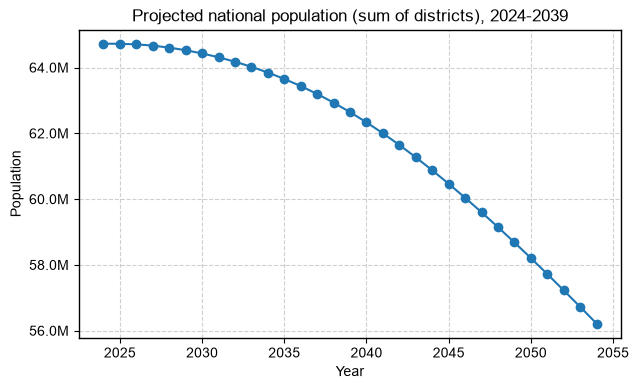

Change 2024-2054: -8,512,187 (-13.2%)


In [9]:
# Sanity check: national total should move gradually, not explode or collapse,
# and should be broadly consistent with Thailand's known low-fertility trajectory.
national = pop_dist_proj.groupby('year')['pop'].sum()

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(national.index, national.values, marker='o')
ax.set_title('Projected national population (sum of districts), 2024-2039')
ax.set_xlabel('Year')
ax.set_ylabel('Population')
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f'{x/1e6:.1f}M'))
ax.grid(True)
plt.show()

print(f"Change {LAST_YEAR}-{LAST_YEAR + HORIZON}: {national.iloc[-1] - national.iloc[0]:+,.0f} "
      f"({(national.iloc[-1] / national.iloc[0] - 1):+.1%})")

In [27]:
# Import Thailand hospital data
hosp_file = 'hosp'
data_dir = 'data'
output_dir = 'output/clean'

hosp, hosp_raw, dict_path = process.DataCleaning.clean(hosp_file, data_dir, output_dir, clear=True)
hosp = hosp[(hosp['status'] != 'ยกเลิก')]
hosp = hosp[hosp['htype'].isin(['โรงพยาบาลเอกชน', 'โรงพยาบาล นอก สธ.', 'โรงพยาบาล นอก สป.สธ.', 'โรงพยาบาลชุมชน', 'โรงพยาบาลทั่วไป', 'โรงพยาบาลศูนย์', 'โรงพยาบาลส่งเสริมสุขภาพตำบล', 'ศูนย์บริการสาธารณสุข อปท.'])].copy()
hosp = hosp[~hosp['hcode'].isna()]
hosp['hcode'] = hosp['hcode'].apply(lambda x: x[2:-1]) #convert hcode from ="xxxxx" to xxxxx

hosp.to_csv('output/clean/hosp_cleaned.csv')

# Hospital descriptive
hosp_total = len(hosp)
hosp_public = len(hosp[hosp['hgroup']=='รัฐบาล'])
hosp_private = len(hosp[hosp['hgroup']=='เอกชน'])

print(
      "----------------------------------------------------",
      "\nTotal hospital:" , hosp_total,
      "\nTotal public hospital:", hosp_public,
      "\nTotal private hospital:", hosp_private,
      "\n----------------------------------------------------")

File name                : hosp
Path to data dictionary  : data/data_dict-hosp.xlsx
Path to cleaned dataset  : output/clean/hosp_cleaned.csv
---------------------------------------------------- 
Total hospital: 11791 
Total public hospital: 11330 
Total private hospital: 461 
----------------------------------------------------


In [39]:
scrp = input("Would you like to run the scraping process? (Y/N): ").strip().upper()
output_dir = 'output/scraped'

if scrp == 'Y':

    hosp_id = pd.DataFrame({
        'hosp_id': hosp['hcode']
    })

    serv_path = scrp_serv.scrap(hosp_id, output_dir, fetch_current_year=True)
    hrh_df = pd.read_csv(serv_path)
    
elif scrp == 'N':
    
    # Use previously saved data
    serv_path = os.path.join(output_dir, 'hrhserv.csv')
    
    if os.path.exists(serv_path):
        hrh_df = pd.read_csv(serv_path)
        print(f"Data from '{serv_path}' has been successfully loaded and processed.")
    else:
        print(f"Error: The file '{serv_path}' does not exist. Please run the scraping first.")

Progress 3114/11791 hcode = 09654:  26%|██▋       | 3114/11791 [58:55<3:55:36,  1.63s/it]

Failed to fetch data for hosp_id 09774 with error: HTTPConnectionPool(host='gishealth.moph.go.th', port=80): Max retries exceeded with url: /healthmap/infoservice.php?maincode=09774&year=2012 (Caused by ConnectTimeoutError(<HTTPConnection(host='gishealth.moph.go.th', port=80) at 0x1799be690>, 'Connection to gishealth.moph.go.th timed out. (connect timeout=None)'))
Retrying...


Progress 8715/11791 hcode = 04822:  74%|███████▍  | 8715/11791 [5:44:31<3:45:53,  4.41s/it] 

Failed to fetch data for hosp_id 04829 with error: HTTPConnectionPool(host='gishealth.moph.go.th', port=80): Max retries exceeded with url: /healthmap/infoservice.php?maincode=04829&year=2019 (Caused by ConnectTimeoutError(<HTTPConnection(host='gishealth.moph.go.th', port=80) at 0x30d1eaf10>, 'Connection to gishealth.moph.go.th timed out. (connect timeout=None)'))
Retrying...


Progress 11791/11791 hcode = 56067: 100%|██████████| 11791/11791 [10:16:09<00:00,  3.14s/it]  


Scraped data have been successfully saved to 'output/scraped/serv.csv'
(Last updated: 2026-07-23 22:24:58).
README updated: 'output/scraped/README_serv.md'


In [38]:
hosp_id_example = pd.DataFrame({'hosp_id': ['41861']})
output_dir = "output/scraped"

# Run the scraper
output_file = scrp_serv.scrap(hosp_id_example, output_dir, fetch_current_year=True)

Progress:   0%|          | 0/1 [00:00<?, ?it/s]

41861


Progress 1/1 hcode = 41861: 100%|██████████| 1/1 [00:00<00:00,  1.47it/s]

Scraped data have been successfully saved to 'output/scraped/serv.csv'
(Last updated: 2026-07-23 12:08:17).
README updated: 'output/scraped/README_serv.md'


In [ ]:
    # # Create population dataset in district level
    # dist = pop[pop['subdist_id'] != 0][['year', 'subdist_id', 'pop']]
    # dist['subdist_id'] = dist['subdist_id'].astype(str)
    # dist['subdist_id'] = dist['subdist_id'].apply(lambda x: x[:-4])
    # dist.rename(columns=lambda x: x.replace('subdist_id', 'dist_id') if x.startswith('subdist_id') else x, inplace=True)
    # dist = dist.groupby(['year', 'dist_id']).sum().reset_index()
    # pop_dist = pd.concat([pop_dist, dist], ignore_index=True)
    # pop_dist.to_csv('output/clean/pop_dist.csv')

    display(pop.head())

    # pop['prov'] = pop['prov'].apply(lambda x: x if x in ['กรุงเทพมหานคร', 'ทั่วประเทศ'] else x[7:])
    # pop['year'] = year
    
    # # Create population dataset in country level
    # country = pop[pop['prov_id'] == 0][['year', 'prov', 'pop']]
    # pop_country = pd.concat([pop_country, country], ignore_index=True)
    # pop_country.to_csv('output/clean/pop_country.csv')
    
    # # Create population dataset in provincial level
    # prov = pop[(pop['prov_id'] != 0) & (pop['dist_id'] == 0) & (pop['subdist_id'] == 0) & (pop['village_id'] == 0)][['year', 'prov', 'prov_id', 'pop']]
    # pop_prov = pd.concat([pop_prov, prov], ignore_index=True)
    # pop_prov.to_csv('output/clean/pop_prov.csv')



    # # Create population dataset in health regional level
    # hregion = prov.copy()
    # hregion = process.DataManipulation.mapping(hregion, 'prov')
    # hregion.rename(columns=lambda x: x.replace('prov', 'hregion') if x.startswith('prov') else x, inplace=True)
    # hregion = hregion.groupby(['year', 'hregion']).sum().reset_index()
    # hregion['hregion_id'] = hregion['hregion'].apply(lambda x: x[-2:] if len(x) == 15 else x[-1:])
    # pop_hregion = pd.concat([pop_hregion, hregion], ignore_index=True)

clear_output()